# [**StaX-Net: Stackelberg Interleaved Asymmetric Network for Cross-Modality Medical Image Translation**](https://arxiv.org/abs/2610.34214)  

---

**Amin Golnari**<sup>a,∗</sup>, **Saeid Sanei**<sup>a,b,c</sup>  

<sup>a</sup> College of Engineering & Computer Science, VinUniversity, Hanoi, Vietnam  
<sup>b</sup> College of Health Science, VinUniversity, Hanoi, Vietnam  
<sup>c</sup> Institute of Psychiatry, Psychology & Neuroscience, King’s College London, UK  

**Link to the preprint version:** [arXiv preprint](https://arxiv.org/abs/2610.34214)


**Run this implementation on Google Colab:**  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/amingolnari/Demo-StaX-Net/blob/main/StaX-Net.ipynb)

---


If our work is helpful to you, please kindly cite our paper as:

```bibtex
@article{golnari2026staxnet,
  title={StaX-Net: Stackelberg Interleaved Asymmetric Network for Cross-Modality Medical Image Translation},
  author={Golnari, Amin and Sanei, Saeid},
  journal={arXiv preprint arXiv:2610.34214},
  doi={https://doi.org/10.48550/arXiv.2610.34214},
  year={2026}
}


⚠️ **Important Note:**

To quickly test the notebook and verify that the code functions correctly, the default configuration has been modified to use only **2% of the dataset** and train for a single **1 epoch**.

To run the full training pipeline, please update the following configuration variables:

```python
SKIP_ALL_PREPROCESSING_AND_CHECKS = False
DOWNLOAD = True
MAX_SUBJECTS = None
DATASET_SUBSET_FRACTION = 1.0

CFG = {
    # ... other settings ...
    "epochs": 100,  # Or your desired number of epochs
    # ... other settings ...
}
```

In [1]:
import os
try:
    from google.colab import drive
    drive.mount('/content/drive/', force_remount=True)
except ImportError:
    print("Not running in Google Colab.")

Mounted at /content/drive/


# StaX-Net on IXI: T1 → T2 MRI Synthesis

Stackelberg cross-modality image synthesis trained on the real **IXI** brain MRI dataset (T1 → T2).

* **Stackelberg optimisation.** The discriminator (leader) updates all of its parameters; the generator (follower) updates only its dedicated parameters, with a faster learning rate. The multi-scale blocks shared by both networks belong to the leader.
* **FAST layer (LUPI).** Target features act as privileged information during training only; inference needs the source image alone.
* **Lazy data loading.** A custom `keras.utils.Sequence` reads each batch's PNGs from disk on the fly (nothing is cached) and yields NumPy arrays in [-1, 1].
* **Training-time augmentation.** Random flip / rotation / translation / zoom applied *jointly* to source and target (switch off with `AUG["enabled"]`).
* **Bypass flag.** `SKIP_ALL_PREPROCESSING_AND_CHECKS = True` skips the pip installs, the download and every verification / preprocessing step when the dataset is already prepared.

**Pipeline:** download IXI → rigid co-registration (T1 onto the T2 grid) → end-slice removal, XY resampling, normalisation to [-1, 1] → paired PNG slices → `Sequence` generators (subject-level 80/20 split) → StaX-Net training → PSNR / SSIM / MAE evaluation.

Requires TensorFlow ≥ 2.16 (Keras 3). `torchio`, `SimpleITK` are needed only when preprocessing is enabled.
> Note: IXI T1 (sagittal) and T2 (axial) volumes are not co-registered, so the co-registration step in Cell 2 is required for valid slice pairs.

## 1. Setup & constants
Run mode (**`SKIP_ALL_PREPROCESSING_AND_CHECKS`**), imports, seeds, paths, preprocessing options, augmentation strength and hyper-parameters. Edit `RAW_DATA_DIR` / `OUTPUT_PNG_DIR` here.

In [2]:
# =====================================================================
# Run mode - master bypass switch
# =====================================================================
# True  -> the dataset is already prepared. Skip the pip installs, the download
#          and ALL file verification / preprocessing / QC (Cell 2). Cell 3 then only
#          lists the existing PNG files, without per-file existence checks.
# False -> full pipeline: install deps, download IXI, co-register, preprocess, QC.
SKIP_ALL_PREPROCESSING_AND_CHECKS = True

if SKIP_ALL_PREPROCESSING_AND_CHECKS:
    print("SKIP_ALL_PREPROCESSING_AND_CHECKS=True -> skipping pip installs.")
else:
    get_ipython().run_line_magic("pip", "install -q simpleitk torchio")

SKIP_ALL_PREPROCESSING_AND_CHECKS=True -> skipping pip installs.


In [3]:
import warnings

warnings.filterwarnings("ignore")
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
os.environ['KMP_WARNINGS'] = '0'

In [4]:
# =====================================================================
# Cell 1 - Setup & Constants
# =====================================================================
import gc
import random
import re
import shutil
import time
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
import keras
import keras.backend as K
from keras import layers
from keras.layers import (
    Add, AveragePooling2D, Concatenate, Conv2D, Conv2DTranspose, Dense,
    Dropout, GlobalAveragePooling2D, Input, Layer, LayerNormalization,
    LeakyReLU, MaxPooling2D, Multiply, SpectralNormalization, UpSampling2D,
)
from keras.models import Model
from tqdm.auto import tqdm

# SimpleITK / TorchIO are only needed by the preprocessing stage (Cell 2).
if not SKIP_ALL_PREPROCESSING_AND_CHECKS:
    import SimpleITK as sitk
    import torchio as tio
    print(f"SimpleITK {sitk.Version_VersionString()} | TorchIO {tio.__version__}")
print(f"TensorFlow {tf.__version__} | Keras {keras.__version__}")
print(f"SKIP_ALL_PREPROCESSING_AND_CHECKS = {SKIP_ALL_PREPROCESSING_AND_CHECKS}")

# ---------------------------------------------------------------------
# Reproducibility
# ---------------------------------------------------------------------
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Let TensorFlow grow GPU memory instead of grabbing it all at once.
for _gpu in tf.config.list_physical_devices("GPU"):
    try:
        tf.config.experimental.set_memory_growth(_gpu, True)
    except RuntimeError:
        pass  # must be set before the GPU is initialised

# ---------------------------------------------------------------------
# Paths
# ---------------------------------------------------------------------
BASE_DIR = "/content/drive/MyDrive/Datasets/IXIDataset"
RAW_DATA_DIR = f"{BASE_DIR}/data/ixi_raw"        # where torchio downloads the IXI NIfTI files
OUTPUT_PNG_DIR = f"{BASE_DIR}/data/ixi_png"      # where the paired PNG slices are written
CKPT_DIR = f"{BASE_DIR}/checkpoints"             # where trained weights are saved

# ---------------------------------------------------------------------
# IXI download / preprocessing configuration
# ---------------------------------------------------------------------
SOURCE_MOD = "T1"                      # input modality
TARGET_MOD = "T2"                      # modality to synthesise
MODALITIES = (SOURCE_MOD, TARGET_MOD)  # downloaded + processed (DTI is 4D: unsupported)
DOWNLOAD = False                       # set False if the NIfTI files are already on disk
                                       # (ignored when SKIP_ALL_PREPROCESSING_AND_CHECKS is True)

# IXI T1 (sagittal) and T2 (axial) are NOT acquired on the same grid and are
# NOT co-registered. Paired slice-to-slice training is only meaningful after
# rigid registration of the source onto the target grid. Keep this True.
COREGISTER = True

TARGET_XY_SHAPE = (256, 256)           # (width, height) after XY resampling
MIN_TISSUE_RATIO = 0.05                # fraction of a slice that must be "tissue"
BG_PERCENTILE = 5                      # tissue threshold = this percentile of non-zero voxels
PNG_COMPRESSION_LEVEL = 3              # 0 (fast, big) ... 9 (slow, small); lossless either way
SKIP_EXISTING = True                   # skip subjects whose PNG folders are already complete
SHOW_QC = True                         # plot one registered pair after preprocessing

# Optional subsampling for quick experiments (None / 1 = use everything).
MAX_SUBJECTS = 10                      # e.g. 100 to process / train on 100 subjects only
SLICE_STRIDE = 1                       # e.g. 2 keeps every 2nd slice of each subject

# ---------------------------------------------------------------------
# Data split
# ---------------------------------------------------------------------
DATASET_SUBSET_FRACTION = 0.02         # fraction of ALL subjects to use, e.g. 0.10 = 10 %.
                                       # Sampled at SUBJECT level (all slices of a chosen subject
                                       # are kept) with SEED, BEFORE the train/test split.
                                       # 1.0 = use every available subject.
TEST_FRACTION = 0.2                    # split by SUBJECT (no slice leakage), applied to the subset

# ---------------------------------------------------------------------
# Model / training hyper-parameters
# ---------------------------------------------------------------------
CFG = {
    "batch_size": 4,
    "epochs": 1,
    "base_filters": 16,       # width of the first stage
    "depth": 4,               # number of encoder/decoder stages (paper: 5)
    "lr_gen": 1.25e-4,        # follower (generator)
    "lr_disc": 1e-4,          # leader (discriminator)
    "beta_1": 0.5,
    "label_smooth_real": 0.9,
    "label_smooth_fake": 0.1,
    "lambda_recon": 15.0,
    "lambda_adv": 1.0,
    "w_l1": 0.4,
    "w_ssim": 0.6,
}

# ---------------------------------------------------------------------
# Training-time augmentation (Cell 5). Applied jointly to the source and target
# slice so the pair stays aligned; never applied at inference / evaluation.
# ---------------------------------------------------------------------
AUG = {
    "enabled": True,
    "rotation": 0.02,       # fraction of 2*pi  -> about +/-7 degrees
    "translation": 0.05,    # fraction of the image size, both axes
    "zoom": 0.10,           # +/-10 %, same factor for both axes
}

IMG_H, IMG_W = TARGET_XY_SHAPE[1], TARGET_XY_SHAPE[0]
IMG_SHAPE = (IMG_H, IMG_W, 1)
assert IMG_H % (2 ** (CFG["depth"] - 1)) == 0 and IMG_W % (2 ** (CFG["depth"] - 1)) == 0, \
    "Image size must be divisible by 2**(depth-1) for the U-Net style skips."

# Number of random test samples shown in the qualitative figure (Cell 7)
assert 0.0 < DATASET_SUBSET_FRACTION <= 1.0, "DATASET_SUBSET_FRACTION must be in (0, 1]."

N_VISUAL = 6

TensorFlow 2.21.0 | Keras 3.13.2
SKIP_ALL_PREPROCESSING_AND_CHECKS = True


## 2. IXI download & preprocessing
Downloads IXI with `torchio`, registers T1 onto the T2 grid, removes empty end-slices (one joint range per subject), resamples XY, normalises globally to [-1, 1] and writes paired PNG slices. Already-processed subjects are skipped.

**Entirely bypassed when `SKIP_ALL_PREPROCESSING_AND_CHECKS = True`** (no download, no verification, no preprocessing, no QC plot).

In [5]:
# =====================================================================
# Cell 2 - IXI Dataset Download & Preprocessing
# =====================================================================
# Entirely bypassed when SKIP_ALL_PREPROCESSING_AND_CHECKS is True (see the guard at the
# bottom of this cell). Per subject:
#   1. Download IXI with torchio (skipped automatically if already present).
#   2. Rigidly register the SOURCE volume onto the TARGET grid (mutual information),
#      so that slice z of both volumes shows the same anatomy.
#   3. Remove empty slices at the Z-axis ENDS ONLY (one joint range for both volumes).
#   4. Resample X/Y to TARGET_XY_SHAPE with BSpline interpolation (Z untouched).
#   5. Global normalisation per volume: clip [0.5, 99.5] percentiles -> [0, 1] -> [-1, 1].
#   6. Save every remaining Z slice as an 8-bit PNG: <OUT>/<MOD>/<subject>/<subject>_slice_NNN.png


# ---------------------------------------------------------------------
# Download
# ---------------------------------------------------------------------
def download_ixi(root_dir):
    """Download IXI via torchio (no-op for files that already exist)."""
    Path(root_dir).mkdir(parents=True, exist_ok=True)
    return tio.datasets.IXI(root=str(root_dir), modalities=MODALITIES, download=True)


# ---------------------------------------------------------------------
# File discovery / pairing by subject
# ---------------------------------------------------------------------
def find_volumes(root_dir):
    """Return sorted list of (modality, path) for all NIfTI files under root_dir."""
    root_dir = Path(root_dir)
    files = []
    for modality in MODALITIES:
        mod_dir = root_dir / modality
        if not mod_dir.is_dir():
            continue
        paths = sorted(list(mod_dir.glob("*.nii.gz")) + list(mod_dir.glob("*.nii")))
        files.extend((modality, p) for p in paths)
    return files


def get_volume_id(path):
    """'IXI002-Guys-0828-T1.nii.gz' -> 'IXI002-Guys-0828-T1'."""
    name = path.name
    for ext in (".nii.gz", ".nii"):
        if name.endswith(ext):
            return name[: -len(ext)]
    return path.stem


def get_subject_id(path):
    """'IXI002-Guys-0828-T1.nii.gz' -> 'IXI002-Guys-0828' (modality suffix removed)."""
    return re.sub(r"-(T1|T2|PD|MRA|DTI)$", "", get_volume_id(path))


def group_by_subject(volumes):
    """{subject_id: {modality: path}} keeping only subjects that have ALL MODALITIES."""
    subjects = {}
    for modality, path in volumes:
        subjects.setdefault(get_subject_id(path), {})[modality] = path
    return {sid: mods for sid, mods in sorted(subjects.items())
            if all(m in mods for m in MODALITIES)}


# ---------------------------------------------------------------------
# Preprocessing functions
# ---------------------------------------------------------------------
def find_valid_z_range(sitk_img, min_tissue_ratio=MIN_TISSUE_RATIO,
                       bg_percentile=BG_PERCENTILE):
    """First / last Z index whose slice contains enough tissue (None if no slice does)."""
    arr = sitk.GetArrayFromImage(sitk_img)  # (Z, Y, X)
    nonzero = arr[arr > 0]
    thresh = np.percentile(nonzero, bg_percentile) if nonzero.size > 0 else 0
    mask = arr > thresh
    tissue_ratio = mask.sum(axis=(1, 2)) / float(arr.shape[1] * arr.shape[2])
    valid = np.where(tissue_ratio > min_tissue_ratio)[0]
    if valid.size == 0:
        return None
    return int(valid[0]), int(valid[-1])


def crop_z(sitk_img, first, last):
    """Continuous crop to [first : last + 1]. Slicing keeps origin/direction/spacing correct."""
    return sitk_img[:, :, first:last + 1]


def remove_empty_end_slices(sitk_img, min_tissue_ratio=MIN_TISSUE_RATIO,
                            bg_percentile=BG_PERCENTILE):
    """Crop empty slices from the two ENDS of the Z axis only (middle slices are kept)."""
    z_range = find_valid_z_range(sitk_img, min_tissue_ratio, bg_percentile)
    return None if z_range is None else crop_z(sitk_img, *z_range)


def resample_image_xy(sitk_img, target_xy_size=TARGET_XY_SHAPE):
    """Resample ONLY X and Y to (width, height) with BSpline; Z size/spacing preserved."""
    orig_size = sitk_img.GetSize()
    if orig_size[0] == target_xy_size[0] and orig_size[1] == target_xy_size[1]:
        return sitk_img

    orig_spacing = sitk_img.GetSpacing()
    new_spacing = [
        orig_spacing[0] * orig_size[0] / target_xy_size[0],
        orig_spacing[1] * orig_size[1] / target_xy_size[1],
        orig_spacing[2],
    ]
    new_size = [int(target_xy_size[0]), int(target_xy_size[1]), int(orig_size[2])]

    resampler = sitk.ResampleImageFilter()
    resampler.SetSize(new_size)
    resampler.SetOutputSpacing(new_spacing)
    resampler.SetOutputOrigin(sitk_img.GetOrigin())
    resampler.SetOutputDirection(sitk_img.GetDirection())
    resampler.SetInterpolator(sitk.sitkBSpline)
    resampler.SetDefaultPixelValue(0)
    return resampler.Execute(sitk_img)


def global_normalize(sitk_img):
    """Whole-volume normalisation: clip at 0.5 / 99.5 percentiles -> [0, 1] -> [-1, 1]."""
    arr = sitk.GetArrayFromImage(sitk_img).astype(np.float64)
    p_low, p_high = np.percentile(arr, 0.5), np.percentile(arr, 99.5)

    if p_high - p_low < 1e-8:
        arr = np.zeros_like(arr)                  # constant volume: avoid division by zero
    else:
        arr = np.clip(arr, p_low, p_high)
        arr = (arr - p_low) / (p_high - p_low)    # [0, 1]
    arr = arr * 2.0 - 1.0                         # [-1, 1]

    new_img = sitk.GetImageFromArray(arr.astype(np.float32))
    new_img.CopyInformation(sitk_img)
    return new_img


# ---------------------------------------------------------------------
# Co-registration (source -> target grid)
# ---------------------------------------------------------------------
def same_grid(a, b):
    """True if two images share size, spacing, origin and direction."""
    return (a.GetSize() == b.GetSize()
            and np.allclose(a.GetSpacing(), b.GetSpacing(), atol=1e-3)
            and np.allclose(a.GetOrigin(), b.GetOrigin(), atol=1e-2)
            and np.allclose(a.GetDirection(), b.GetDirection(), atol=1e-3))


def coregister_to_fixed(moving, fixed):
    """Rigid (6-DOF) mutual-information registration of `moving` onto the grid of `fixed`.

    The target (fixed) image is never interpolated, so ground truth stays untouched;
    only the input modality is resampled. Returns (resampled_moving, final_metric).
    If both images already share a grid (e.g. PD -> T2) nothing is done.
    """
    if same_grid(moving, fixed):
        return moving, None

    fixed_f = sitk.Cast(fixed, sitk.sitkFloat32)
    moving_f = sitk.Cast(moving, sitk.sitkFloat32)

    init_tx = sitk.CenteredTransformInitializer(
        fixed_f, moving_f, sitk.Euler3DTransform(),
        sitk.CenteredTransformInitializerFilter.MOMENTS)

    reg = sitk.ImageRegistrationMethod()
    reg.SetMetricAsMattesMutualInformation(numberOfHistogramBins=50)
    reg.SetMetricSamplingStrategy(reg.RANDOM)
    reg.SetMetricSamplingPercentage(0.1, SEED)
    reg.SetInterpolator(sitk.sitkLinear)
    reg.SetOptimizerAsRegularStepGradientDescent(
        learningRate=1.0, minStep=1e-4, numberOfIterations=200,
        gradientMagnitudeTolerance=1e-8)
    reg.SetOptimizerScalesFromPhysicalShift()
    reg.SetShrinkFactorsPerLevel([4, 2, 1])
    reg.SetSmoothingSigmasPerLevel([2, 1, 0])
    reg.SmoothingSigmasAreSpecifiedInPhysicalUnitsOn()
    reg.SetInitialTransform(init_tx, inPlace=False)

    final_tx = reg.Execute(fixed_f, moving_f)
    resampled = sitk.Resample(moving_f, fixed_f, final_tx, sitk.sitkBSpline, 0.0,
                              sitk.sitkFloat32)
    return resampled, reg.GetMetricValue()


# ---------------------------------------------------------------------
# PNG conversion
# ---------------------------------------------------------------------
def normalize_to_uint8(slice_2d, min_val=-1.0, max_val=1.0):
    """Map a 2D float slice from [min_val, max_val] to uint8 [0, 255]."""
    arr = np.array(slice_2d, dtype=np.float32, copy=True)
    arr = np.nan_to_num(arr, nan=min_val, posinf=max_val, neginf=min_val)
    np.clip(arr, min_val, max_val, out=arr)
    arr = (arr - min_val) / (max_val - min_val) * 255.0
    return np.rint(arr).astype(np.uint8)


def save_png(img_uint8, out_path):
    """Save a uint8 image as PNG using cv2.imencode (robust to non-ASCII paths)."""
    ok, buf = cv2.imencode(".png", img_uint8,
                           [int(cv2.IMWRITE_PNG_COMPRESSION), int(PNG_COMPRESSION_LEVEL)])
    if not ok:
        raise IOError(f"Failed to encode PNG: {out_path}")
    Path(out_path).write_bytes(buf.tobytes())


def convert_volume_to_png_slices(sitk_img, output_dir, subject_id):
    """Save every Z slice of a [-1, 1] volume as <subject>_slice_001.png, ... Returns count."""
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    arr = sitk.GetArrayFromImage(sitk_img)  # (Z, Y, X)
    for z in range(arr.shape[0]):
        save_png(normalize_to_uint8(arr[z], -1.0, 1.0),
                 output_dir / f"{subject_id}_slice_{z + 1:03d}.png")
    return arr.shape[0]


# ---------------------------------------------------------------------
# Main preprocessing loop
# ---------------------------------------------------------------------
def _subject_done(out_root, subject_id):
    """True if every modality folder exists and all folders hold the same, non-zero PNG count."""
    counts = []
    for m in MODALITIES:
        d = out_root / m / subject_id
        counts.append(len(list(d.glob("*.png"))) if d.is_dir() else 0)
    return counts[0] > 0 and len(set(counts)) == 1


def preprocess_ixi():
    if DOWNLOAD:
        download_ixi(RAW_DATA_DIR)

    subjects = group_by_subject(find_volumes(RAW_DATA_DIR))
    if not subjects:
        raise RuntimeError(f"No complete {MODALITIES} subjects found under {RAW_DATA_DIR}")
    subject_ids = list(subjects)[:MAX_SUBJECTS] if MAX_SUBJECTS else list(subjects)

    out_root = Path(OUTPUT_PNG_DIR)
    out_root.mkdir(parents=True, exist_ok=True)
    stats = {"processed": 0, "skipped": 0, "failed": 0, "pngs": 0}
    reg_metrics = {}

    for sid in tqdm(subject_ids, desc="Processing IXI subjects", unit="subj"):
        if SKIP_EXISTING and _subject_done(out_root, sid):
            stats["skipped"] += 1
            continue
        try:
            src = sitk.ReadImage(str(subjects[sid][SOURCE_MOD]))
            trg = sitk.ReadImage(str(subjects[sid][TARGET_MOD]))
            if src.GetDimension() != 3 or trg.GetDimension() != 3:
                tqdm.write(f"[SKIP] {sid}: not a 3D volume.")
                stats["skipped"] += 1
                continue

            # a) Bring source onto the target grid
            if COREGISTER:
                src, metric = coregister_to_fixed(src, trg)
                reg_metrics[sid] = metric
            elif not same_grid(src, trg):
                tqdm.write(f"[SKIP] {sid}: {SOURCE_MOD}/{TARGET_MOD} grids differ "
                           f"and COREGISTER=False.")
                stats["skipped"] += 1
                continue

            # b) Remove empty END slices, using ONE joint range so slice z matches in both
            r_src, r_trg = find_valid_z_range(src), find_valid_z_range(trg)
            if r_src is None or r_trg is None:
                tqdm.write(f"[SKIP] {sid}: no tissue slices found.")
                stats["skipped"] += 1
                continue
            first, last = max(r_src[0], r_trg[0]), min(r_src[1], r_trg[1])
            if first > last:
                tqdm.write(f"[SKIP] {sid}: no overlapping tissue range.")
                stats["skipped"] += 1
                continue

            written = {}
            for mod, vol in ((SOURCE_MOD, src), (TARGET_MOD, trg)):
                vol = crop_z(vol, first, last)
                vol = resample_image_xy(vol, TARGET_XY_SHAPE)   # c) XY only (BSpline)
                vol = global_normalize(vol)                      # d) [-1, 1]
                written[mod] = convert_volume_to_png_slices(     # e) PNGs
                    vol, out_root / mod / sid, sid)
            assert written[SOURCE_MOD] == written[TARGET_MOD]
            stats["pngs"] += sum(written.values())
            stats["processed"] += 1

        except Exception as e:  # noqa: BLE001
            tqdm.write(f"[ERROR] {sid}: {e}")
            for m in MODALITIES:                       # drop partial output of this subject
                shutil.rmtree(out_root / m / sid, ignore_errors=True)
            stats["failed"] += 1
        finally:
            src = trg = vol = None
            gc.collect()

    print("\n" + "=" * 60)
    print("Done.")
    print(f"  Processed subjects : {stats['processed']}")
    print(f"  Skipped subjects   : {stats['skipped']}")
    print(f"  Failed subjects    : {stats['failed']}")
    print(f"  PNG slices saved   : {stats['pngs']}")
    print(f"  Output directory   : {out_root}")
    print("=" * 60)
    return subject_ids, reg_metrics


def _read_png_gray(path):
    return cv2.imdecode(np.fromfile(str(path), dtype=np.uint8), cv2.IMREAD_GRAYSCALE)


def show_registration_qc(subject_id):
    """Visual check of the pair at the middle slice: source | target | overlay."""
    src_dir = Path(OUTPUT_PNG_DIR) / SOURCE_MOD / subject_id
    trg_dir = Path(OUTPUT_PNG_DIR) / TARGET_MOD / subject_id
    files = sorted(p.name for p in src_dir.glob("*.png"))
    name = files[len(files) // 2]
    s, t = _read_png_gray(src_dir / name), _read_png_gray(trg_dir / name)
    overlay = np.dstack([s, t, s])  # magenta = source only, green = target only
    fig, ax = plt.subplots(1, 3, figsize=(10, 3.6))
    for a, img, title in zip(ax, (s, t, overlay),
                             (SOURCE_MOD, TARGET_MOD, "Overlay (alignment check)")):
        a.imshow(img, cmap=None if img.ndim == 3 else "gray")
        a.set_title(f"{title}\n{subject_id}" if title == SOURCE_MOD else title)
        a.axis("off")
    plt.tight_layout()
    plt.show()


if SKIP_ALL_PREPROCESSING_AND_CHECKS:
    print("SKIP_ALL_PREPROCESSING_AND_CHECKS=True -> download, verification, "
          "preprocessing and QC skipped.")
    print(f"Using the existing dataset in: {OUTPUT_PNG_DIR}")
    processed_subjects, registration_metrics = [], {}
else:
    processed_subjects, registration_metrics = preprocess_ixi()
    if SHOW_QC and processed_subjects:
        show_registration_qc(processed_subjects[0])

SKIP_ALL_PREPROCESSING_AND_CHECKS=True -> download, verification, preprocessing and QC skipped.
Using the existing dataset in: /content/drive/MyDrive/Datasets/IXIDataset/data/ixi_png


## 3. Custom data generator & train/test split
Subjects are first reduced to `DATASET_SUBSET_FRACTION` of the total (random, seeded, **subject level**), then split 80/20 *within that subset* (no patient appears in both sets). `PairedPNGSequence` subclasses `keras.utils.Sequence` (= `tf.keras.utils.Sequence`) and reads **only the PNG files of the requested batch from disk** inside `__getitem__`; nothing is cached in memory. Batches are NumPy arrays scaled to **[-1, 1]**. With `SKIP_ALL_PREPROCESSING_AND_CHECKS = True` the file listing does no per-file existence checks.

In [6]:
# =====================================================================
# Cell 3 - Custom Sequence data generator & subject-level Train/Test split
# =====================================================================
from concurrent.futures import ThreadPoolExecutor


def list_pairs_by_subject(png_root, src_mod, trg_mod, verify=True):
    """{subject_id: [(src_png, trg_png), ...]}.

    verify=True  : keep only slices present in BOTH modalities (one stat call per file).
    verify=False : trust the prepared dataset and pair files by name, no existence checks
                   (much faster on network drives such as Google Drive).
    """
    src_root, trg_root = Path(png_root) / src_mod, Path(png_root) / trg_mod
    if not src_root.is_dir() or not trg_root.is_dir():
        raise FileNotFoundError(
            f"Expected {src_root} and {trg_root}. Run Cell 2 first "
            f"(SKIP_ALL_PREPROCESSING_AND_CHECKS = False) or fix OUTPUT_PNG_DIR.")
    pairs = {}
    for subj_dir in sorted(p for p in src_root.iterdir() if p.is_dir()):
        trg_dir = trg_root / subj_dir.name
        src_files = sorted(subj_dir.glob("*.png"))
        if verify:
            if not trg_dir.is_dir():
                continue
            src_files = [sp for sp in src_files if (trg_dir / sp.name).exists()]
        subj_pairs = [(str(sp), str(trg_dir / sp.name)) for sp in src_files]
        if subj_pairs:
            pairs[subj_dir.name] = subj_pairs
    return pairs


def split_subjects(subject_ids, test_fraction, seed):
    """Random subject-level split, so no patient appears in both train and test."""
    ids = sorted(subject_ids)
    random.Random(seed).shuffle(ids)
    n_test = min(max(1, int(round(len(ids) * test_fraction))), len(ids) - 1)
    return sorted(ids[n_test:]), sorted(ids[:n_test])


def sample_subject_subset(subject_ids, fraction, seed):
    """Reproducible random SUBJECT-level subset.

    Parameters
    ----------
    subject_ids : iterable of str
        All available subject ids.
    fraction : float
        Fraction of subjects to keep, in (0, 1]. At least 2 subjects are kept so that
        the subsequent train/test split has a non-empty train AND test set.
    seed : int
        Seed of a private RNG (the global RNG state is left untouched).

    Returns
    -------
    list of str
        Sorted ids of the selected subjects (all of their slices are kept downstream).
    """
    ids = sorted(subject_ids)
    if not 0.0 < fraction <= 1.0:
        raise ValueError(f"fraction must be in (0, 1], got {fraction}")
    if fraction == 1.0:
        return ids
    n_keep = min(len(ids), max(2, int(round(len(ids) * fraction))))
    return sorted(random.Random(seed).sample(ids, n_keep))


class PairedPNGSequence(keras.utils.Sequence):
    """Lazy (source, target) PNG batch generator (``keras.utils.Sequence``).

    Only the file *paths* are stored. ``__getitem__`` reads the PNGs of ONE batch from
    disk with OpenCV and returns them as float32 NumPy arrays scaled to [-1, 1]; no image
    is kept after the batch is returned, so memory use is O(batch_size).

    Parameters
    ----------
    pairs : list of (str, str)
        ``(source_png_path, target_png_path)`` tuples.
    batch_size : int
        Samples per batch.
    shuffle : bool, optional
        Reshuffle the sample order every time ``on_epoch_end`` is called.
    drop_remainder : bool, optional
        Drop the last incomplete batch (fixed batch size -> no ``tf.function`` retracing).
    seed : int, optional
        Seed of the shuffling RNG.
    num_threads : int, optional
        Threads used to read the files of one batch in parallel (OpenCV releases the GIL).
    """

    def __init__(self, pairs, batch_size, shuffle=False, drop_remainder=False,
                 seed=0, num_threads=4, **kwargs):
        super().__init__(**kwargs)
        self.pairs = list(pairs)
        self.batch_size = int(batch_size)
        self.shuffle = shuffle
        self.drop_remainder = drop_remainder
        self._rng = np.random.default_rng(seed)
        self._pool = ThreadPoolExecutor(num_threads) if num_threads > 1 else None
        self.indices = np.arange(len(self.pairs))
        self.on_epoch_end()                       # initial shuffle

    def __len__(self):
        n = len(self.pairs)
        return n // self.batch_size if self.drop_remainder else -(-n // self.batch_size)

    @staticmethod
    def _read_png(path):
        """Read ONE grayscale PNG from disk -> float32 (H, W, 1) in [-1, 1]."""
        buf = np.fromfile(path, dtype=np.uint8)               # robust to non-ASCII paths
        img = cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE)
        if img is None:
            raise IOError(f"Could not read PNG: {path}")
        return (img.astype(np.float32) / 127.5 - 1.0)[..., None]

    def __getitem__(self, idx):
        if not 0 <= idx < len(self):
            raise IndexError(f"Batch index {idx} out of range [0, {len(self)})")
        sel = self.indices[idx * self.batch_size:(idx + 1) * self.batch_size]
        paths = [self.pairs[i] for i in sel]
        read = self._pool.map if self._pool else map
        src = np.stack(list(read(self._read_png, [p[0] for p in paths])))
        trg = np.stack(list(read(self._read_png, [p[1] for p in paths])))
        return src, trg

    def __iter__(self):
        for i in range(len(self)):
            yield self[i]

    def on_epoch_end(self):
        """Reshuffle sample order (a custom training loop must call this itself)."""
        if self.shuffle:
            self._rng.shuffle(self.indices)


pairs_by_subject = list_pairs_by_subject(
    OUTPUT_PNG_DIR, SOURCE_MOD, TARGET_MOD,
    verify=not SKIP_ALL_PREPROCESSING_AND_CHECKS)
all_subjects = sorted(pairs_by_subject)
n_available = len(all_subjects)

# 1) Reduce to the requested fraction of ALL subjects (subject level, seeded) ...
all_subjects = sample_subject_subset(all_subjects, DATASET_SUBSET_FRACTION, SEED)
print(f"Subject subset: {len(all_subjects)} of {n_available} subjects "
      f"(DATASET_SUBSET_FRACTION = {DATASET_SUBSET_FRACTION})")

if MAX_SUBJECTS and len(all_subjects) > MAX_SUBJECTS:
    all_subjects = sorted(random.Random(SEED).sample(all_subjects, MAX_SUBJECTS))

# 2) ... then split train/test exclusively within that subset.
train_subjects, test_subjects = split_subjects(all_subjects, TEST_FRACTION, SEED)
train_pairs = [p for s in train_subjects for p in pairs_by_subject[s][::SLICE_STRIDE]]
test_pairs = [p for s in test_subjects for p in pairs_by_subject[s][::SLICE_STRIDE]]

train_gen = PairedPNGSequence(train_pairs, CFG["batch_size"], shuffle=True,
                             drop_remainder=True, seed=SEED)
test_gen = PairedPNGSequence(test_pairs, CFG["batch_size"], shuffle=False,
                             drop_remainder=False)

print(f"Subjects  -> train: {len(train_subjects)} | test: {len(test_subjects)}")
print(f"Slice pairs -> train: {len(train_pairs):,} | test: {len(test_pairs):,}")
print(f"Batches   -> train: {len(train_gen):,} | test: {len(test_gen):,}")

_src, _trg = train_gen[0]                       # reads just one batch from disk
print(f"Batch: src {_src.shape} {_src.dtype} | trg {_trg.shape} {_trg.dtype}")
print(f"Range: src [{_src.min():.2f}, {_src.max():.2f}] | trg [{_trg.min():.2f}, {_trg.max():.2f}]")
del _src, _trg


Subject subset: 12 of 577 subjects (DATASET_SUBSET_FRACTION = 0.02)
Subjects  -> train: 8 | test: 2
Slice pairs -> train: 1,040 | test: 260
Batches   -> train: 260 | test: 65
Batch: src (4, 256, 256, 1) float32 | trg (4, 256, 256, 1) float32
Range: src [-1.00, 1.00] | trg [-1.00, 1.00]


## 4. StaX-Net architecture
FAST layer, dedicated / shared multi-scale blocks, hybrid up-sampling and `build_staxnet`, followed by instantiation and a smoke test. The generator maps `[source, target]` to the synthesised image; the target is privileged information consumed only by the FAST auxiliary loss, so it has no effect at inference. The shared multi-scale blocks are the *same layer instances* in both networks.

In [7]:
# =====================================================================
# Cell 4 - StaX-Net architecture
# =====================================================================

class FAST(Layer):
    """Feature Aggregation and Spatial Transformation (FAST) layer.

    Target-supervised prior distillation under the LUPI paradigm, followed by
    FiLM modulation and AdaIN re-normalisation of the source features.

    Parameters
    ----------
    loss_weight : float, optional
        Weight of the prior-distillation loss registered via ``add_loss``.
    use_film : bool, optional
        Enable FiLM modulation of the prior.
    **kwargs
        Standard ``keras.layers.Layer`` arguments.

    Notes
    -----
    ``call`` takes ``[content, reference]``. ``reference`` contributes only to
    the auxiliary loss when ``training=True``.
    """

    def __init__(self, loss_weight=0.25, use_film=True, **kwargs):
        super().__init__(**kwargs)
        self.loss_weight = loss_weight
        self.use_film = use_film

    def build(self, input_shape):
        c = (input_shape[0][-1] if isinstance(input_shape, list)
             else input_shape[-1])

        # Prior generator: expand -> (3x3 + dilated 3x3) -> SE -> project
        self.prior_expand = Conv2D(c, 1, padding="same", name="prior_expand")
        self.prior_ln_exp = LayerNormalization(axis=-1, name="prior_ln_exp")
        self.prior_conv3 = Conv2D(2 * c, 3, padding="same", name="prior_conv3")
        self.prior_conv_dil = Conv2D(2 * c, 3, padding="same",
                                     dilation_rate=2, name="prior_conv_dil")
        self.prior_ln_conv = LayerNormalization(axis=-1, name="prior_ln_conv")
        self.se_pool = GlobalAveragePooling2D(keepdims=True)
        self.se_dense1 = Dense(max(8, c // 2), activation="relu",
                               name="se_dense1")
        self.se_dense2 = Dense(2 * c, activation="sigmoid", name="se_dense2")
        self.prior_project = Conv2D(c, 1, padding="same", name="prior_project")
        self.prior_ln_proj = LayerNormalization(axis=-1, name="prior_ln_proj")
        self.act = LeakyReLU(0.2)

        self.fusion_conv = Conv2D(c, 1, padding="same", name="fusion_conv")

        if self.use_film:   # (mean, std) descriptor of size 2C -> gamma, beta
            self.conv_gamma = Conv2D(c, 1, name="film_gamma")
            self.conv_beta = Conv2D(c, 1, name="film_beta")
        super().build(input_shape)

    def prior_distillation_loss(self, reference, prior):
        """0.5 * L1 + 0.5 * finite-difference gradient matching."""
        l1 = tf.reduce_mean(tf.abs(prior - reference))
        dx_p = prior[:, :, 1:, :] - prior[:, :, :-1, :]
        dy_p = prior[:, 1:, :, :] - prior[:, :-1, :, :]
        dx_r = reference[:, :, 1:, :] - reference[:, :, :-1, :]
        dy_r = reference[:, 1:, :, :] - reference[:, :-1, :, :]
        grad = (0.5 * tf.reduce_mean(tf.square(dx_p - dx_r))
                + 0.5 * tf.reduce_mean(tf.square(dy_p - dy_r)))
        loss = 0.5 * l1 + 0.5 * grad
        return tf.where(tf.math.is_nan(loss), l1, loss)

    def call(self, inputs, training=None):
        content, reference = inputs[0], inputs[1]

        # Spatial prior
        x = self.act(self.prior_ln_exp(self.prior_expand(content)))
        x = self.act(self.prior_ln_conv(
            self.prior_conv3(x) + self.prior_conv_dil(x)))
        x = x * self.se_dense2(self.se_dense1(self.se_pool(x)))
        prior = content + self.prior_ln_proj(self.prior_project(x))

        # FiLM
        mu_c, var_c = tf.nn.moments(content, axes=[1, 2], keepdims=True)
        std_c = tf.sqrt(tf.maximum(var_c, 0.0) + K.epsilon())
        if self.use_film:
            stats = tf.concat([mu_c, std_c], axis=-1)
            prior_bank = ((1.0 + self.conv_gamma(stats)) * prior
                          + self.conv_beta(stats))
        else:
            prior_bank = prior

        # AdaIN
        mu_p, var_p = tf.nn.moments(prior_bank, axes=[1, 2], keepdims=True)
        std_p = tf.sqrt(tf.maximum(var_p, 0.0) + K.epsilon())
        styled = (content - mu_c) / (std_c + K.epsilon()) * std_p + mu_p

        out = self.act(self.fusion_conv(
            tf.concat([styled, prior_bank], axis=-1)))

        if training:   # privileged supervision: loss only
            self.add_loss(self.loss_weight
                          * self.prior_distillation_loss(reference, prior))
        return out

    def get_config(self):
        config = super().get_config()
        config.update({"loss_weight": self.loss_weight,
                       "use_film": self.use_film})
        return config


def dedicated_block(x, filters, name_prefix, use_sn=False):
    """Dedicated block: residual unit followed by multi-scale residual unit.

    Parameters
    ----------
    x : keras.KerasTensor
        Input feature map.
    filters : int
        Number of output channels.
    name_prefix : str
        Prefix for unique layer names.
    use_sn : bool, optional
        Use spectral normalisation instead of layer normalisation.

    Returns
    -------
    keras.KerasTensor
        Output feature map with ``filters`` channels.
    """
    def conv_layer(f, k, **kwargs):
        conv = Conv2D(f, k, **kwargs)
        return SpectralNormalization(conv) if use_sn else conv

    def norm(t, name):
        return t if use_sn else LayerNormalization(axis=-1, name=name)(t)

    # --- Residual unit ---
    shortcut = x
    in_ch = int(x.shape[-1])

    h = conv_layer(filters, 3, padding="same", use_bias=False,
                   name=f"{name_prefix}_res_conv1")(x)
    h = LeakyReLU(0.2, name=f"{name_prefix}_res_relu1")(
        norm(h, f"{name_prefix}_res_ln1"))
    h = conv_layer(filters, 3, padding="same", use_bias=False,
                   name=f"{name_prefix}_res_conv2")(h)
    h = norm(h, f"{name_prefix}_res_ln2")

    if in_ch != filters:
        shortcut = conv_layer(filters, 1, padding="same", use_bias=False,
                              name=f"{name_prefix}_res_shortcut")(shortcut)
        shortcut = norm(shortcut, f"{name_prefix}_res_shortcut_ln")

    res_out = LeakyReLU(0.2, name=f"{name_prefix}_res_out")(
        Add(name=f"{name_prefix}_res_add")([h, shortcut]))

    # --- Multi-scale residual unit ---
    ms_shortcut = res_out
    branch_filters = max(8, filters // 3) or 8

    b_in = conv_layer(filters, 1, padding="same", use_bias=False,
                      name=f"{name_prefix}_ms_in_conv")(res_out)
    b_in = LeakyReLU(0.2, name=f"{name_prefix}_ms_in_relu")(
        norm(b_in, f"{name_prefix}_ms_in_ln"))

    # Local branch (3x3)
    b1 = conv_layer(branch_filters, 3, padding="same", use_bias=False,
                    name=f"{name_prefix}_ms_local")(b_in)
    b1 = LeakyReLU(0.2, name=f"{name_prefix}_ms_local_relu")(
        norm(b1, f"{name_prefix}_ms_local_ln"))

    # Cascaded branch (two 3x3, 5x5 receptive field)
    b2 = conv_layer(branch_filters, 3, padding="same", use_bias=False,
                    name=f"{name_prefix}_ms_casc1")(b_in)
    b2 = LeakyReLU(0.2, name=f"{name_prefix}_ms_casc1_relu")(
        norm(b2, f"{name_prefix}_ms_casc1_ln"))
    b2 = conv_layer(branch_filters, 3, padding="same", use_bias=False,
                    name=f"{name_prefix}_ms_casc2")(b2)
    b2 = LeakyReLU(0.2, name=f"{name_prefix}_ms_casc2_relu")(
        norm(b2, f"{name_prefix}_ms_casc2_ln"))

    # Dilated branch (3x3, dilation 2)
    b3 = conv_layer(branch_filters, 3, dilation_rate=2, padding="same",
                    use_bias=False, name=f"{name_prefix}_ms_dilated")(b_in)
    b3 = LeakyReLU(0.2, name=f"{name_prefix}_ms_dilated_relu")(
        norm(b3, f"{name_prefix}_ms_dilated_ln"))

    fused = Concatenate(name=f"{name_prefix}_ms_concat")([b1, b2, b3])
    fused = LeakyReLU(0.2, name=f"{name_prefix}_ms_fuse_relu")(
        norm(fused, f"{name_prefix}_ms_fuse_ln"))

    proj = conv_layer(filters, 1, padding="same", use_bias=False,
                      name=f"{name_prefix}_ms_proj")(fused)
    proj = norm(proj, f"{name_prefix}_ms_proj_ln")

    if int(res_out.shape[-1]) != filters:
        ms_shortcut = conv_layer(
            filters, 1, padding="same", use_bias=False,
            name=f"{name_prefix}_ms_shortcut")(ms_shortcut)
        ms_shortcut = norm(ms_shortcut, f"{name_prefix}_ms_shortcut_ln")

    return LeakyReLU(0.2, name=f"{name_prefix}_ms_out")(
        Add(name=f"{name_prefix}_ms_add")([proj, ms_shortcut]))


class SharedMultiScaleBlock(Layer):
    """Multi-scale block shared by the generator and the discriminator.

    The same layer instance is called in both networks, so its parameters are
    common variables. Under the Stackelberg formulation they are owned by the
    leader (discriminator); the follower (generator) reads them in the forward
    pass but does not update them. All convolutions are spectrally normalised.

    Parameters
    ----------
    filters : int
        Number of channels of every branch and of the output.
    stage_id : int
        Stage index, used for layer naming.
    **kwargs
        Standard ``keras.layers.Layer`` arguments.
    """

    def __init__(self, filters, stage_id, **kwargs):
        super().__init__(**kwargs)
        self.filters = filters
        self.stage_id = stage_id
        p = f"shared_s{stage_id}"

        def sn_conv(f, k, name, **kw):
            return SpectralNormalization(
                Conv2D(f, k, padding="same", name=f"{p}_{name}_conv", **kw),
                name=f"{p}_{name}_sn")

        self.conv_in = sn_conv(filters, 1, "in", use_bias=False)
        self.b1_conv = sn_conv(filters, 3, "b1", use_bias=False)
        self.b2_conv1 = sn_conv(filters, 3, "b2a", use_bias=False)
        self.b2_conv2 = sn_conv(filters, 3, "b2b", use_bias=False)
        self.b3_conv = sn_conv(filters, 3, "b3", use_bias=False,
                               dilation_rate=2)
        self.fuse_conv = sn_conv(filters, 1, "fuse", use_bias=False)
        self.out_conv = sn_conv(filters, 1, "out", use_bias=False)
        self.sc_conv = sn_conv(filters, 1, "sc", use_bias=False)

        # Squeeze-and-excitation gate
        self.se_gap = GlobalAveragePooling2D(keepdims=True,
                                             name=f"{p}_se_gap")
        self.se_conv1 = sn_conv(max(4, filters // 4), 1, "se1",
                                activation="relu", use_bias=True)
        self.se_conv2 = sn_conv(filters, 1, "se2",
                                activation="sigmoid", use_bias=True)

        self.act = LeakyReLU(0.2, name=f"{p}_act")
        self.concat = Concatenate(axis=-1, name=f"{p}_concat")
        self.se_multiply = Multiply(name=f"{p}_se_multiply")
        self.add_layer = Add(name=f"{p}_add")

    def build(self, input_shape):
        super().build(input_shape)

    def call(self, inputs):
        shortcut = inputs
        in_ch = inputs.shape[-1]

        y = self.act(self.conv_in(inputs))
        b1 = self.act(self.b1_conv(y))
        b2 = self.act(self.b2_conv2(self.act(self.b2_conv1(y))))
        b3 = self.act(self.b3_conv(y))

        fused = self.act(self.fuse_conv(self.concat([b1, b2, b3])))
        fused = self.out_conv(fused)

        se = self.se_conv2(self.se_conv1(self.se_gap(fused)))
        out = self.se_multiply([fused, se])

        if in_ch is None or int(in_ch) != self.filters:
            shortcut = self.sc_conv(shortcut)
        return self.act(self.add_layer([out, shortcut]))

    def get_config(self):
        config = super().get_config()
        config.update({"filters": self.filters, "stage_id": self.stage_id})
        return config


def hybrid_upsampling(x, filters, upscale_factor=2, name_prefix="hybrid_up"):
    """Hybrid up-sampling: bilinear branch + transposed-convolution branch.

    Parameters
    ----------
    x : keras.KerasTensor
        Input feature map.
    filters : int
        Number of output channels.
    upscale_factor : int, optional
        Spatial up-sampling factor.
    name_prefix : str, optional
        Prefix for unique layer names.

    Returns
    -------
    keras.KerasTensor
        Feature map up-sampled by ``upscale_factor``.
    """
    def conv3(t, name):
        return Conv2D(filters, 3, padding="same", use_bias=False,
                      name=f"{name_prefix}_{name}")(t)

    def ln_act(t, name):
        t = LayerNormalization(axis=-1, name=f"{name_prefix}_{name}_ln")(t)
        return LeakyReLU(0.2, name=f"{name_prefix}_{name}_relu")(t)

    b1 = UpSampling2D(size=(upscale_factor, upscale_factor),
                      interpolation="bilinear",
                      name=f"{name_prefix}_bilinear")(x)
    b1 = ln_act(conv3(b1, "b1_conv"), "b1")

    b2 = Conv2DTranspose(filters, upscale_factor, strides=upscale_factor,
                         padding="same", use_bias=False,
                         name=f"{name_prefix}_transposed")(x)
    b2 = ln_act(b2, "b2_trans")
    b2 = ln_act(conv3(b2, "b2_refine"), "b2_refine")

    fused = Add(name=f"{name_prefix}_add")([b1, b2])
    return ln_act(conv3(fused, "post_fuse"), "post_fuse")


def build_staxnet(input_shape, base_filters=16, depth=4):
    """Build the StaX-Net generator and discriminator.

    Parameters
    ----------
    input_shape : tuple of int
        Image shape ``(H, W, C)``.
    base_filters : int, optional
        Filters in the first stage; doubled at each subsequent stage.
    depth : int, optional
        Number of encoder / decoder stages (the last encoder stage is the
        bottleneck).

    Returns
    -------
    generator : keras.Model
        Maps ``[source, target]`` to the synthesised image. ``target`` is
        privileged information used only by the FAST auxiliary losses.
        ``generator.shared_variables`` lists the variables shared with the
        discriminator.
    discriminator : keras.Model
        Maps an image to a single real/fake logit.
    """
    multipliers = [2 ** i for i in range(depth)]          # [1, 2, 4, 8, ...]

    # Shared multi-scale blocks, referenced by both networks.
    shared_blocks = [
        SharedMultiScaleBlock(base_filters * m, stage_id=i + 1,
                              name=f"shared_block_{i + 1}")
        for i, m in enumerate(multipliers)
    ]

    # ===================== Discriminator (leader) =====================
    d_in = Input(shape=input_shape, name="disc_input")
    dx = dedicated_block(d_in, max(8, base_filters // 2),
                         "disc_input_block", use_sn=True)

    for i, m in enumerate(multipliers, 1):
        f = base_filters * m
        dx = dedicated_block(dx, f, f"disc_dedicated_{i}", use_sn=True)
        dx = shared_blocks[i - 1](dx)
        dx = MaxPooling2D((2, 2), name=f"disc_pool_{i}")(dx)

    h = GlobalAveragePooling2D(name="disc_gap")(dx)
    h = Dropout(0.2)(LeakyReLU(0.2)(Dense(256)(h)))
    h = Dropout(0.2)(LeakyReLU(0.2)(Dense(128)(h)))
    logits = Dense(1, name="disc_logits")(h)
    discriminator = Model(d_in, logits, name="StaXNet_Discriminator")

    # ====================== Generator (follower) ======================
    src_in = Input(shape=input_shape, name="src_input")
    trg_in = Input(shape=input_shape, name="trg_input")   # privileged (LUPI)

    def project_target(t, f, tag):
        """1x1 conv + LN + LeakyReLU: target -> FAST reference space."""
        t = Conv2D(f, 1, padding="same", use_bias=False,
                   name=f"gen_trg_conv_{tag}")(t)
        t = LayerNormalization(axis=-1, name=f"gen_trg_ln_{tag}")(t)
        return LeakyReLU(0.2, name=f"gen_trg_relu_{tag}")(t)

    gx_fast = src_in
    gx_shared = None
    trg_pooled = trg_in
    skips = []

    # Encoder and bottleneck
    for i, m in enumerate(multipliers, 1):
        f = base_filters * m

        if i == 1:
            gx_enc = dedicated_block(gx_fast, f, f"gen_dedicated_e{i}")
            gx_shared = shared_blocks[i - 1](gx_enc)
        else:
            # Dedicated path on the pooled shared output
            pool_shared = MaxPooling2D(
                (2, 2), name=f"gen_pool_shared_e{i}")(gx_shared)
            enc_shared = dedicated_block(pool_shared, f,
                                         f"gen_dedicated_e{i}")
            # FAST path
            pool_fast = MaxPooling2D(
                (2, 2), name=f"gen_pool_fast_e{i}")(gx_fast)

            concat_in = Concatenate(name=f"gen_concat_e{i}")(
                [enc_shared, pool_fast])
            # 1x1 fusion to the stage width expected by the shared block
            fused_in = Conv2D(f, 1, padding="same", use_bias=False,
                              name=f"gen_fuse_conv_e{i}")(concat_in)
            fused_in = LeakyReLU(0.2, name=f"gen_fuse_relu_e{i}")(
                LayerNormalization(axis=-1,
                                   name=f"gen_fuse_ln_e{i}")(fused_in))
            gx_shared = shared_blocks[i - 1](fused_in)

            # Match the target resolution to the current stage
            trg_pooled = AveragePooling2D(
                (2, 2), name=f"gen_trg_pool_e{i}")(trg_pooled)

        gx_fast = FAST(name=f"gen_fast_e{i}")(
            [gx_shared, project_target(trg_pooled, f, f"e{i}")])

        if i < len(multipliers):
            skips.append(gx_fast)
        else:
            gd = gx_fast                                   # bottleneck

    # Decoder
    for i, m in enumerate(reversed(multipliers[:-1]), 1):
        f = base_filters * m
        gd = hybrid_upsampling(gd, f, 2, f"gen_hybrid_up_{i}")
        gd = Concatenate(name=f"gen_skip_concat_{i}")([gd, skips[-i]])
        gd = dedicated_block(gd, f, f"gen_dedicated_d{i}")

    # Output head
    head = dedicated_block(gd, base_filters, "gen_output_head")
    out = Conv2D(input_shape[-1], 3, padding="same", activation="tanh",
                 name="gen_output_img")(head)
    generator = Model([src_in, trg_in], out, name="StaXNet_Generator")

    # Leader-owned variables: read, not updated, by the generator.
    generator.shared_variables = [
        v for block in shared_blocks for v in block.trainable_variables
    ]
    return generator, discriminator


# ---- Instantiate and smoke-test (privileged input must not matter at inference) ----
generator, discriminator = build_staxnet(
    IMG_SHAPE, CFG["base_filters"], CFG["depth"])

src = tf.random.uniform((CFG["batch_size"], *IMG_SHAPE), -1.0, 1.0)
trg = tf.random.uniform((CFG["batch_size"], *IMG_SHAPE), -1.0, 1.0)

fake = generator([src, trg], training=False)
logit = discriminator(fake, training=False)
print("Source:", src.shape, "| Target:", trg.shape)
print("Generator output:", fake.shape, "| Discriminator output:", logit.shape)
print(f"Generator params: {generator.count_params():,} | "
      f"Discriminator params: {discriminator.count_params():,}")

# Inference does not depend on the privileged target.
fake_zero = generator([src, tf.zeros_like(trg)], training=False)
print("max|G(x, y) - G(x, 0)| =",
      float(tf.reduce_max(tf.abs(fake - fake_zero))))

Source: (4, 256, 256, 1) | Target: (4, 256, 256, 1)
Generator output: (4, 256, 256, 1) | Discriminator output: (4, 1)
Generator params: 3,000,575 | Discriminator params: 1,538,942
max|G(x, y) - G(x, 0)| = 0.0


## 5. Stackelberg training setup
* **Variable separation.** Leader = `discriminator.trainable_variables` (dedicated + shared). Follower = `generator.trainable_variables` minus the shared ones, filtered by object identity. Assertions check that the two sets are disjoint and that every shared variable is leader-owned.
* **Augmentation.** `prepare_pair` applies the random layers jointly to the source and target slice (one shared transform per sample) in the training step only.
* **Step.** Leader update first; then the follower's forward pass is recomputed (the shared blocks changed) and only the dedicated generator variables are updated.

In [8]:
# =====================================================================
# Cell 5 - Stackelberg training setup
# =====================================================================

# ---------------------------------------------------------------------
# Training-time augmentation: ONE random transform per sample, shared by source and target
# (they are stacked as channels). Never used at inference / evaluation.
# ---------------------------------------------------------------------
def build_augment_layers():
    if not AUG["enabled"]:
        return []
    return [
        layers.RandomFlip("horizontal", seed=SEED, name="aug_flip"),
        layers.RandomRotation(AUG["rotation"], fill_mode="constant",
                              fill_value=-1.0, seed=SEED + 1, name="aug_rotate"),
        layers.RandomTranslation(AUG["translation"], AUG["translation"],
                                 fill_mode="constant", fill_value=-1.0,
                                 seed=SEED + 2, name="aug_translate"),
        layers.RandomZoom(AUG["zoom"], fill_mode="constant",
                          fill_value=-1.0, seed=SEED + 3, name="aug_zoom"),
    ]


aug_layers = build_augment_layers()


def prepare_pair(src_in, trg_in, training):
    """(src, trg) in [-1, 1] -> jointly augmented (src, trg) when ``training``."""
    src_in = tf.convert_to_tensor(src_in, tf.float32)
    trg_in = tf.convert_to_tensor(trg_in, tf.float32)
    if not training or not aug_layers:
        return src_in, trg_in
    c = IMG_SHAPE[-1]
    pair = tf.concat([src_in, trg_in], axis=-1)
    for layer in aug_layers:
        pair = layer(pair, training=True)
    return pair[..., :c], pair[..., c:]


# ---------------------------------------------------------------------
# Leader / follower variable separation (object identity, see notes in the review)
# ---------------------------------------------------------------------
disc_vars = discriminator.trainable_variables         # leader: dedicated + shared
_shared_ids = {id(v) for v in generator.shared_variables}
gen_vars = [v for v in generator.trainable_variables
            if id(v) not in _shared_ids]                       # follower: dedicated only
gen_vars = list({id(v): v for v in gen_vars}.values())         # defensive de-duplication

_disc_ids = {id(v) for v in disc_vars}
_gen_ids = {id(v) for v in gen_vars}
assert len(_disc_ids) == len(disc_vars), "Duplicate variables in the leader list."
assert len(_gen_ids) == len(gen_vars), "Duplicate variables in the follower list."
assert _shared_ids <= _disc_ids, "Every shared variable must be owned by the leader."
assert _shared_ids <= {id(v) for v in generator.trainable_variables}, \
    "shared_variables must be a subset of the generator's variables."
assert not (_gen_ids & _disc_ids), "Follower and leader variable sets must be disjoint."
assert not (_gen_ids & _shared_ids), "Follower must not hold shared variables."
print(f"Leader variables: {len(disc_vars)} | "
      f"Follower variables: {len(gen_vars)} | "
      f"Shared (frozen for follower): {len(_shared_ids)}")

gen_optimizer = keras.optimizers.Adam(CFG["lr_gen"], beta_1=CFG["beta_1"])
disc_optimizer = keras.optimizers.Adam(CFG["lr_disc"], beta_1=CFG["beta_1"])
gen_optimizer.build(gen_vars)
disc_optimizer.build(disc_vars)
adv_loss = keras.losses.MeanSquaredError()


def smooth_labels(shape, is_real, lo=CFG["label_smooth_real"],
                  hi=CFG["label_smooth_fake"]):
    """Sample smoothed labels: U(lo, 1) if real, U(0, hi) if fake."""
    low, high = (lo, 1.0) if is_real else (0.0, hi)
    return tf.random.uniform(shape, low, high)


def reconstruction_loss(y_true, y_pred):
    """Weighted L1 + (1 - SSIM) for images in [-1, 1]."""
    y_true = tf.clip_by_value(y_true, -1.0, 1.0)
    y_pred = tf.clip_by_value(y_pred, -1.0, 1.0)
    l1 = tf.reduce_mean(tf.abs(y_true - y_pred))
    ssim = tf.reduce_mean(tf.image.ssim(y_true, y_pred, max_val=2.0))
    ssim = tf.where(tf.math.is_nan(ssim), 0.0, ssim)
    return CFG["w_l1"] * l1 + CFG["w_ssim"] * (1.0 - ssim)


@tf.function
def stackelberg_train_step(src_in, trg_in, real_labels, fake_labels, target_labels):
    """One 1:1 leader-follower update on a [-1, 1] batch (NumPy or tensors).

    Returns
    -------
    tuple of tf.Tensor
        Discriminator loss, generator adversarial loss, generator
        reconstruction loss (weighted).
    """
    # Joint augmentation of the pair (training only)
    src, trg = prepare_pair(src_in, trg_in, training=True)

    # Leader: discriminator update (dedicated + shared parameters)
    with tf.GradientTape() as tape_d:
        fake = generator([src, trg], training=True)
        loss_d = 0.5 * (
            adv_loss(real_labels, discriminator(trg, training=True))
            + adv_loss(fake_labels,
                       discriminator(tf.stop_gradient(fake), training=True)))
    disc_optimizer.apply_gradients(
        zip(tape_d.gradient(loss_d, disc_vars), disc_vars))

    # Follower: best response over dedicated parameters only. The forward
    # pass is recomputed because the shared blocks changed.
    with tf.GradientTape() as tape_g:
        fake = generator([src, trg], training=True)
        l_adv = CFG["lambda_adv"] * adv_loss(
            target_labels, discriminator(fake, training=True))
        l_rec = CFG["lambda_recon"] * reconstruction_loss(trg, fake)
        l_fast = (tf.add_n(generator.losses) if generator.losses
                  else tf.constant(0.0))
        loss_g = l_adv + l_rec + l_fast
    gen_optimizer.apply_gradients(
        zip(tape_g.gradient(loss_g, gen_vars), gen_vars))
    return loss_d, l_adv, l_rec


disc_output_shape = discriminator.output_shape[1:]

Leader variables: 95 | Follower variables: 384 | Shared (frozen for follower): 44


### 5b. Follower-isolation self-check (optional, run once before training)
Runs the follower's forward / backward pass exactly as in the training step **without applying any optimiser update**, then verifies that the shared (leader-owned) variables were not modified. A non-zero change would mean something other than the optimiser (e.g. a layer's training-mode side effect) writes to the shared weights.

In [9]:
# =====================================================================
# Cell 5b - Follower-isolation self-check
# =====================================================================
RUN_SEPARATION_CHECK = True


def check_follower_isolation():
    """Follower forward/backward WITHOUT an optimiser step; report changes to shared state."""
    blocks = [l for l in generator.layers if isinstance(l, SharedMultiScaleBlock)]
    shared_tv = [v for b in blocks for v in b.trainable_variables]
    shared_ntv = [v for b in blocks for v in b.non_trainable_variables]  # e.g. SN vectors
    assert {id(v) for v in shared_tv} == {id(v) for v in generator.shared_variables}, \
        "generator.shared_variables does not match the shared blocks found in the model."

    snap = lambda vs: [v.numpy().copy() for v in vs]
    max_delta = lambda a, b: max([float(np.max(np.abs(x - y))) for x, y in zip(a, b)] or [0.0])
    tv0, ntv0 = snap(shared_tv), snap(shared_ntv)

    src_np, trg_np = train_gen[0]
    src, trg = prepare_pair(src_np, trg_np, training=True)
    with tf.GradientTape() as tape:
        fake = generator([src, trg], training=True)
        loss = tf.reduce_mean(tf.abs(fake - trg))
    grads = tape.gradient(loss, gen_vars)                  # follower sources only

    d_tv = max_delta(snap(shared_tv), tv0)
    d_ntv = max_delta(snap(shared_ntv), ntv0)
    print(f"Follower variables without gradient     : {sum(g is None for g in grads)} / {len(grads)}")
    print(f"Max |change| shared trainable variables : {d_tv:.3e}")
    print(f"Max |change| shared non-trainable state : {d_ntv:.3e}")
    if d_tv > 0 or d_ntv > 0:
        print("-> The follower's forward pass modifies shared state even though no optimiser "
              "step was applied (typically SpectralNormalization's training-mode update).")
    else:
        print("-> Shared state untouched by the follower's forward/backward pass.")


if RUN_SEPARATION_CHECK:
    check_follower_isolation()

Follower variables without gradient     : 12 / 384
Max |change| shared trainable variables : 1.545e-01
Max |change| shared non-trainable state : 6.487e-01
-> The follower's forward pass modifies shared state even though no optimiser step was applied (typically SpectralNormalization's training-mode update).


## 6. Training loop & curves
Iterates over the `train_gen` `Sequence` (NumPy batches in [-1, 1], read from disk on the fly), logs the discriminator / generator losses per epoch, saves weights and plots the curves.

Epoch 01/1:   0%|          | 0/260 [00:00<?, ?it/s]

Epoch 01/1 | D: 0.1254 | G-adv: 0.5255 | G-recon: 4.2262 | 2254s
Weights saved to /content/drive/MyDrive/Datasets/IXIDataset/checkpoints


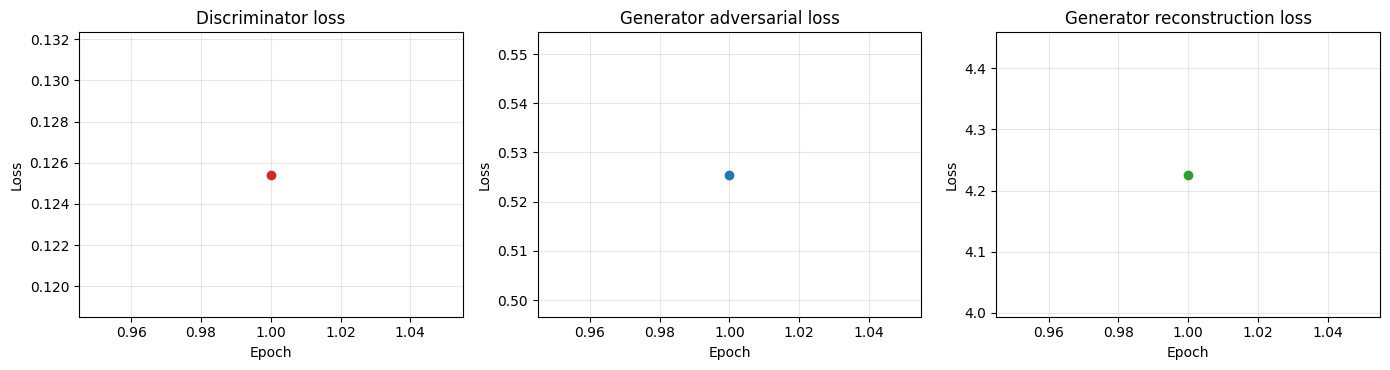

In [10]:
# =====================================================================
# Cell 6 - Training loop & curves
# =====================================================================
history = {"d_loss": [], "g_adv": [], "g_recon": []}
steps_per_epoch = len(train_gen)
t0 = time.time()

for epoch in range(1, CFG["epochs"] + 1):
    d_ep, adv_ep, rec_ep = [], [], []
    pbar = tqdm(train_gen, total=steps_per_epoch, leave=False,
                desc=f"Epoch {epoch:02d}/{CFG['epochs']}")
    for src, trg in pbar:
        b = (src.shape[0], *disc_output_shape)
        real_l = smooth_labels(b, True, CFG["label_smooth_real"], CFG["label_smooth_fake"])
        fake_l = smooth_labels(b, False, CFG["label_smooth_real"], CFG["label_smooth_fake"])
        mislead_l = smooth_labels(b, True, CFG["label_smooth_real"], CFG["label_smooth_fake"])

        d_l, adv_l, rec_l = stackelberg_train_step(src, trg, real_l, fake_l, mislead_l)
        d_ep.append(float(d_l))
        adv_ep.append(float(adv_l))
        rec_ep.append(float(rec_l))
        pbar.set_postfix(D=f"{d_ep[-1]:.3f}", rec=f"{rec_ep[-1]:.3f}")

    train_gen.on_epoch_end()          # reshuffle (a custom loop must call this itself)

    history["d_loss"].append(np.mean(d_ep))
    history["g_adv"].append(np.mean(adv_ep))
    history["g_recon"].append(np.mean(rec_ep))
    print(f"Epoch {epoch:02d}/{CFG['epochs']} | "
          f"D: {history['d_loss'][-1]:.4f} | "
          f"G-adv: {history['g_adv'][-1]:.4f} | "
          f"G-recon: {history['g_recon'][-1]:.4f} | "
          f"{time.time() - t0:.0f}s")

# Save weights
os.makedirs(CKPT_DIR, exist_ok=True)
generator.save_weights(os.path.join(CKPT_DIR, "staxnet_generator.weights.h5"))
discriminator.save_weights(os.path.join(CKPT_DIR, "staxnet_discriminator.weights.h5"))
print(f"Weights saved to {CKPT_DIR}")

# Training curves
epochs_axis = np.arange(1, len(history["d_loss"]) + 1)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
curves = [("d_loss", "Discriminator loss", "tab:red"),
          ("g_adv", "Generator adversarial loss", "tab:blue"),
          ("g_recon", "Generator reconstruction loss", "tab:green")]
for ax, (key, title, color) in zip(axes, curves):
    ax.plot(epochs_axis, history[key], marker="o", color=color, lw=2)
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.set_ylabel("Loss")
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 7. Quantitative & qualitative evaluation
Predicts T2 from T1 with a zeroed privileged target, reports mean PSNR / SSIM / MAE on `test_gen` (images in [0, 1]) and plots Input | Ground Truth | Prediction | Absolute error.

Max |G(x, y) - G(x, 0)| = 0.0


Evaluating:   0%|          | 0/65 [00:00<?, ?it/s]


Test set: 2 subjects, 260 slices  (T1 -> T2)
PSNR : 14.66 +/- 5.30 dB
SSIM : 0.5242 +/- 0.1138
MAE  : 0.1010 +/- 0.0334   (images in [0, 1])


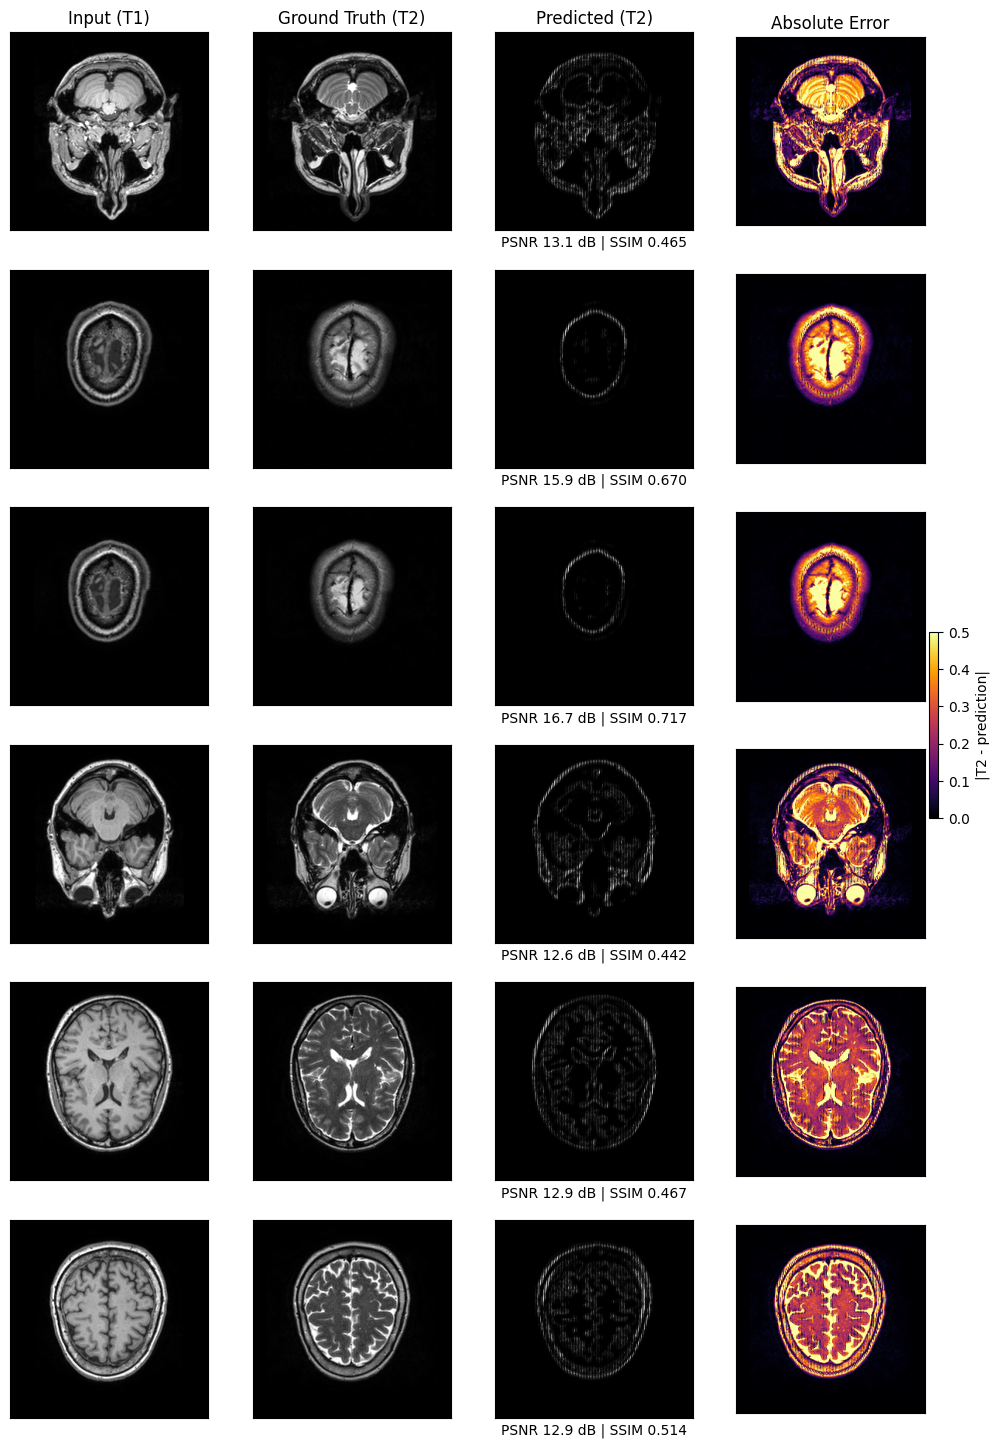

In [11]:
# =====================================================================
# Cell 7 - Quantitative & qualitative evaluation on test_gen
# =====================================================================
def to_unit_range(x):
    """Denormalise [-1, 1] -> [0, 1]."""
    return tf.clip_by_value((x + 1.0) / 2.0, 0.0, 1.0)


# Privileged-information check: the output must not depend on the target at inference.
# The Sequence yields NumPy; Keras 3 forbids mixing NumPy and tensors inside one list of
# inputs, so convert every generator input to a tensor first.
_s, _t = (tf.convert_to_tensor(a) for a in test_gen[0])
_p_real = generator([_s, _t], training=False)
_p_zero = generator([_s, tf.zeros_like(_t)], training=False)
print("Max |G(x, y) - G(x, 0)| =", float(tf.reduce_max(tf.abs(_p_real - _p_zero))))

n_test = len(test_pairs)
n_visual = min(N_VISUAL, n_test)
visual_idx = set(np.random.default_rng(SEED).choice(n_test, size=n_visual, replace=False).tolist())

psnr_all, ssim_all, mae_all = [], [], []
visuals = {}
offset = 0
for src, trg in tqdm(test_gen, desc="Evaluating"):
    src, trg = tf.convert_to_tensor(src), tf.convert_to_tensor(trg)   # no NumPy/tensor mixing
    pred = generator([src, tf.zeros_like(trg)], training=False)   # zeroed privileged target
    src01, gt01, pred01 = to_unit_range(src), to_unit_range(trg), to_unit_range(pred)

    psnr_all.append(tf.image.psnr(gt01, pred01, max_val=1.0).numpy())
    ssim_all.append(tf.image.ssim(gt01, pred01, max_val=1.0).numpy())
    mae_all.append(tf.reduce_mean(tf.abs(gt01 - pred01), axis=[1, 2, 3]).numpy())

    for j in range(src.shape[0]):
        if offset + j in visual_idx:
            visuals[offset + j] = (src01[j, ..., 0].numpy(), gt01[j, ..., 0].numpy(),
                                   pred01[j, ..., 0].numpy())
    offset += src.shape[0]

psnr_all = np.concatenate(psnr_all)
ssim_all = np.concatenate(ssim_all)
mae_all = np.concatenate(mae_all)
finite = np.isfinite(psnr_all)   # PSNR is inf for a pixel-perfect (e.g. all-black) match

print(f"\nTest set: {len(test_subjects)} subjects, {offset:,} slices  ({SOURCE_MOD} -> {TARGET_MOD})")
print(f"PSNR : {psnr_all[finite].mean():.2f} +/- {psnr_all[finite].std():.2f} dB")
print(f"SSIM : {ssim_all.mean():.4f} +/- {ssim_all.std():.4f}")
print(f"MAE  : {mae_all.mean():.4f} +/- {mae_all.std():.4f}   (images in [0, 1])")

# Qualitative figure: [Input, Ground truth, Prediction, |error|]
col_titles = [f"Input ({SOURCE_MOD})", f"Ground Truth ({TARGET_MOD})",
              f"Predicted ({TARGET_MOD})", "Absolute Error"]
rows = sorted(visuals)
fig, axes = plt.subplots(len(rows), 4, figsize=(12, 3 * len(rows)), squeeze=False)
for r, idx in enumerate(rows):
    x, gt, pr = visuals[idx]
    err = np.abs(gt - pr)
    for c, img in enumerate((x, gt, pr)):
        axes[r, c].imshow(img, cmap="gray", vmin=0, vmax=1)
    im = axes[r, 3].imshow(err, cmap="inferno", vmin=0, vmax=0.5)
    axes[r, 2].set_xlabel(f"PSNR {psnr_all[idx]:.1f} dB | SSIM {ssim_all[idx]:.3f}")
    for c in range(4):
        axes[r, c].set_xticks([])
        axes[r, c].set_yticks([])
        if r == 0:
            axes[r, c].set_title(col_titles[c], fontsize=12)
fig.colorbar(im, ax=axes[:, 3], fraction=0.046, pad=0.02, label=f"|{TARGET_MOD} - prediction|")
plt.show()